    User ID  Gender  Age  EstimatedSalary  Purchased
0  15624510    Male   19            19000          0
1  15810944    Male   35            20000          0
2  15668575  Female   26            43000          0
3  15603246  Female   27            57000          0
4  15804002    Male   19            76000          0
Accuracy: 0.87
Confusion Matrix:
 [[59  5]
 [ 8 28]]
Classification Report:
               precision    recall  f1-score   support

           0       0.88      0.92      0.90        64
           1       0.85      0.78      0.81        36

    accuracy                           0.87       100
   macro avg       0.86      0.85      0.86       100
weighted avg       0.87      0.87      0.87       100



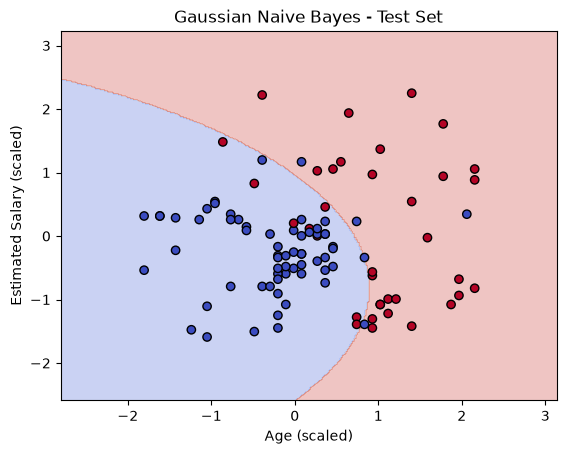

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 1. Load data
df = pd.read_csv("D:\BDA 20\BDA LAB\AIML-BDA-Lab-Work\AssignmentFiles\data\Social_Network_Ads.csv")
print(df.head())

# 2. Features and target
X = df[["Age", "EstimatedSalary"]]
y = df["Purchased"]

# 3. Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# 4. Scale features (not required for NB, but helps the plot)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 5. Train Gaussian Naive Bayes
nb = GaussianNB()
nb.fit(X_train, y_train)

# 6. Predict and evaluate
y_pred = nb.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))

# 7. Plot decision boundary on the test set
x_min, x_max = X_test[:, 0].min() - 1, X_test[:, 0].max() + 1
y_min, y_max = X_test[:, 1].min() - 1, X_test[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                     np.arange(y_min, y_max, 0.02))
Z = nb.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap="coolwarm", edgecolors="k")
plt.xlabel("Age (scaled)")
plt.ylabel("Estimated Salary (scaled)")
plt.title("Gaussian Naive Bayes - Test Set")
plt.show()